# 05 — Concentração do mercado de DNS autoritativo

**Pergunta:** o DNS autoritativo das maiores empresas do mundo está concentrado em poucos
provedores? Isso muda conforme o bloco de origem da empresa (EUA, UE, BRICS, Outros)?

**Escopo:** apenas IPv4. Provedor = grupo econômico dono do ASN (`dp_as_org`, depois do de-para).

**Duas ponderações, sempre lado a lado:** cada gráfico é gerado duas vezes na mesma célula,
uma por **empresas** (participação de mercado: cada empresa vale 1) e outra por **receita**
(cada empresa vale a sua `revenue_ttm`).

**Medidas usadas (todas calculadas para cada bloco e para o total):**
- **Participação de mercado** de cada provedor: a fatia das empresas (ou da receita) que ele atende.
- **HHI** (índice Herfindahl-Hirschman): soma dos quadrados das participações (em %). Vai de
  perto de 0 (mercado pulverizado) a 10.000 (um único provedor atende todo mundo).
  As diretrizes antitruste dos EUA costumam usar ~1.000 e ~1.800 como referências entre
  mercado pouco, moderadamente e altamente concentrado (confirmar a versão vigente antes de citar).
- **Nº efetivo de provedores** = 10.000 ÷ HHI: "o mercado se comporta como se houvesse N
  provedores do mesmo tamanho". É a tradução mais intuitiva do HHI.
- **Fatia dos maiores**: quanto do mercado fica com o 1º provedor, com os 5 maiores e com os 10 maiores.

## 1. Configuração e carga dos dados

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------------------------------------------------------
# CONFIGURAÇÕES
# -----------------------------------------------------------------------------

# Como contar uma empresa que usa mais de um provedor de DNS.
# Exemplo: empresa com 4 NS, sendo 3 na Cloudflare e 1 na AWS.
#   "fracionado" -> a empresa vale 1, dividido pelo nº de NS  (Cloudflare 0,75 | AWS 0,25)
#   "principal"  -> a empresa vale 1, inteiro para o provedor com mais NS  (Cloudflare 1)
#   "uso"        -> a empresa conta 1 para cada provedor que usa  (Cloudflare 1 | AWS 1)
METODO = "fracionado"

# Todo gráfico sai em DUAS versões, geradas na mesma célula (um gráfico para cada):
#   "empresas" -> cada empresa pesa 1: participação de mercado (market share)
#   "receita"  -> cada empresa pesa a sua receita (revenue_ttm), ou seja, "quanto da economia"
# o valor do dicionário é o texto usado nos eixos dos gráficos
PONDERACOES = {"empresas": "companies", "receita": "revenue"}

# pastas de saída (tabelas em CSV e figuras em PNG)
PASTA_TAB = Path("../data/analysis")
PASTA_FIG = Path("../outputs/figures")
PASTA_TAB.mkdir(parents=True, exist_ok=True)
PASTA_FIG.mkdir(parents=True, exist_ok=True)

print("Método:", METODO, "| ponderações:", ", ".join(PONDERACOES))

Método: fracionado | ponderações: empresas, receita


In [88]:
# -----------------------------------------------------------------------------
# PAÍSES E BLOCOS
# -----------------------------------------------------------------------------
# O CompaniesMarketCap informa o país da empresa por extenso ("Brazil"), enquanto o
# país do provedor vem em código ISO de 2 letras ("BR"). Para conseguir comparar os
# dois, converto o país da empresa para o código ISO.
PAIS_ISO2 = {
    "Argentina": "AR", "Australia": "AU", "Austria": "AT", "Bahamas": "BS", "Bahrain": "BH",
    "Belgium": "BE", "Bermuda": "BM", "Brazil": "BR", "British Virgin Islands": "VG",
    "Bulgaria": "BG", "Canada": "CA", "Cayman Islands": "KY", "Chile": "CL", "China": "CN",
    "Colombia": "CO", "Costa Rica": "CR", "Cyprus": "CY", "Czech Republic": "CZ",
    "Denmark": "DK", "Egypt": "EG", "Estonia": "EE", "Finland": "FI", "France": "FR",
    "Germany": "DE", "Gibraltar": "GI", "Greece": "GR", "Guernsey": "GG", "Hong Kong": "HK",
    "Hungary": "HU", "Iceland": "IS", "India": "IN", "Indonesia": "ID", "Ireland": "IE",
    "Isle of Man": "IM", "Israel": "IL", "Italy": "IT", "Japan": "JP", "Jersey": "JE",
    "Jordan": "JO", "Kazakhstan": "KZ", "Kuwait": "KW", "Latvia": "LV",
    "Liechtenstein": "LI", "Lithuania": "LT", "Luxembourg": "LU", "Macau": "MO",
    "Malaysia": "MY", "Malta": "MT", "Mexico": "MX", "Monaco": "MC", "Netherlands": "NL",
    "New Zealand": "NZ", "Norway": "NO", "Panama": "PA", "Peru": "PE", "Philippines": "PH",
    "Poland": "PL", "Portugal": "PT", "Qatar": "QA", "Romania": "RO", "Saudi Arabia": "SA",
    "Singapore": "SG", "South Africa": "ZA", "South Korea": "KR", "Spain": "ES",
    "Sweden": "SE", "Switzerland": "CH", "Taiwan": "TW", "Thailand": "TH", "Turkey": "TR",
    "United Arab Emirates": "AE", "United Kingdom": "GB", "United States": "US",
    "Uruguay": "UY", "Vietnam": "VN", "Russia": "RU", "Ethiopia": "ET", "Iran": "IR",
}

# União Europeia (27 países)
UE27 = {"AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "GR", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"}

# BRICS: os 5 membros originais + os membros plenos que entraram em 2024/2025
# (deixei a Arábia Saudita de fora, porque a adesão formal dela é ambígua; parceiros não entram)
BRICS = {"BR", "RU", "IN", "CN", "ZA", "EG", "ET", "IR", "AE", "ID"}


def bloco_de(pais):
    """Recebe um código ISO de país e devolve o bloco: US, EU, BRICS ou Others."""
    if pais == "US":
        return "US"
    # alguns registros WHOIS trazem "EU" como país (registro regional europeu)
    if pais in UE27 or pais == "EU":
        return "EU"
    if pais in BRICS:
        return "BRICS"
    return "Others"


# ordem em que os blocos aparecem nas tabelas e gráficos ("Total" = todas as empresas)
ORDEM_BLOCOS = ["US", "EU", "BRICS", "Others", "Total"]
# PALETA PADRÃO DO TRABALHO: "tab10" do matplotlib. Todas as cores dos gráficos saem daqui.
#   0 azul | 1 laranja | 2 verde | 3 vermelho | 4 roxo | 5 marrom | 6 rosa | 7 cinza | 8 oliva | 9 ciano
PALETA = plt.get_cmap("tab10").colors

CORES_BLOCOS = {"US": PALETA[0], "EU": PALETA[1], "BRICS": PALETA[2],
                "Others": PALETA[7], "Total": PALETA[4]}

In [89]:
# -----------------------------------------------------------------------------
# ESTILO DOS GRÁFICOS E FUNÇÕES PARA SALVAR
# -----------------------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,      # tiro as bordas de cima e da direita
    "axes.spines.right": False,
    "axes.grid": True,             # grade horizontal leve, ajuda a ler os valores
    "axes.grid.axis": "y",
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "legend.frameon": False,
})


def salvar_tabela(tabela, nome, pond):
    """Salva a tabela em CSV, com o método e a ponderação no nome (ex.: _fracionado_receita)."""
    tabela.to_csv(PASTA_TAB / f"{nome}_{METODO}_{pond}.csv")


def salvar_figura(fig, nome, pond):
    """Salva a figura em PNG, com o método e a ponderação no nome (ex.: _fracionado_receita)."""
    fig.savefig(PASTA_FIG / f"{nome}_{METODO}_{pond}.png", dpi=200, bbox_inches="tight")


def rotulos_com_n(n_por_bloco):
    """Cria os rótulos do eixo X no formato 'US\n(n=3,257)'."""
    return [f"{b}\n(n={n:,})" for b, n in n_por_bloco.items()]

In [90]:
# lê o dataset final (uma linha por empresa x NS x IP)
df = pd.read_parquet("../data/final/final_data.parquet")

# fico apenas com os endereços IPv4 (registros do tipo "A")
df = df[df["ip_type"] == "A"].copy()

# país e bloco da EMPRESA (onde fica a sede)
df["pais_empresa"] = df["company_country"].map(PAIS_ISO2)
df["bloco_empresa"] = df["pais_empresa"].apply(bloco_de)

# PROVEDOR = grupo econômico dono do ASN (já com o de-para aplicado)
df["provedor"] = df["dp_as_org"]
df["pais_provedor"] = df["dp_as_country_code"]
df["bloco_provedor"] = df["pais_provedor"].apply(bloco_de)

# conferência: nenhum país pode ter ficado sem código ISO
assert df["pais_empresa"].notna().all(), "há países sem código ISO no dicionário"

print(f"{len(df):,} linhas IPv4 | {df['rank'].nunique():,} empresas | {df['provedor'].nunique():,} provedores")

44,069 linhas IPv4 | 10,283 empresas | 1,112 provedores


## 2. Tabela base: uma linha por empresa × provedor

Aqui eu resumo o dataset em uma tabela com **uma linha para cada par (empresa, provedor)**,
contando quantos NS a empresa tem em cada provedor. Depois aplico o `METODO` escolhido para
definir o **peso** de cada linha:

| Método | O que significa o peso | A soma dos pesos de uma empresa |
|---|---|---|
| `fracionado` | nº de NS no provedor ÷ nº total de NS da empresa | 1 |
| `principal` | 1 só para o provedor com mais NS (os outros saem) | 1 |
| `uso` | 1 para cada provedor que a empresa usa | nº de provedores da empresa |

Por fim, multiplico o peso pelo peso da empresa nas duas ponderações, o que gera as colunas
**`valor_empresas`** (peso × 1, participação de mercado) e **`valor_receita`** (peso × receita),
que são as que todas as análises somam. Cada gráfico é gerado uma vez para cada ponderação.

In [91]:
# 1) uma linha por (empresa, provedor), contando quantos NS a empresa tem naquele provedor
ep = (df.groupby(["rank", "provedor"], as_index=False)
        .agg(company_name=("company_name", "first"),
             revenue_ttm=("revenue_ttm", "first"),
             pais_empresa=("pais_empresa", "first"),
             bloco_empresa=("bloco_empresa", "first"),
             pais_provedor=("pais_provedor", "first"),
             bloco_provedor=("bloco_provedor", "first"),
             n_ns=("ns", "nunique")))

# 2) peso de cada linha, conforme o método escolhido lá em cima
if METODO == "fracionado":
    # nº de NS no provedor dividido pelo total de NS da empresa
    ep["peso"] = ep["n_ns"] / ep.groupby("rank")["n_ns"].transform("sum")

elif METODO == "principal":
    # ordeno por empresa e, dentro dela, do provedor com mais NS para o com menos;
    # depois fico só com a primeira linha de cada empresa (em caso de empate, vale a ordem alfabética)
    ep = (ep.sort_values(["rank", "n_ns", "provedor"], ascending=[True, False, True])
            .drop_duplicates("rank"))
    ep["peso"] = 1.0

elif METODO == "uso":
    ep["peso"] = 1.0

# 3) peso da empresa nas duas ponderações (1 ou a receita) e o valor que as análises somam
ep["peso_empresas"] = 1
ep["peso_receita"] = ep["revenue_ttm"]
for pond in PONDERACOES:
    ep[f"valor_{pond}"] = ep["peso"] * ep[f"peso_{pond}"]

# 4) para ter a coluna "Total" nas comparações, duplico a tabela trocando o bloco por "Total".
#    Assim, todo groupby por bloco já devolve US, EU, BRICS, Others e Total de uma vez.
base = pd.concat([ep, ep.assign(bloco_empresa="Total")], ignore_index=True)

# nº de empresas de cada bloco (usado nos rótulos dos gráficos)
n_empresas = base.groupby("bloco_empresa")["rank"].nunique().reindex(ORDEM_BLOCOS)
display(n_empresas.to_frame("n_companies"))

# exemplo: algumas empresas que usam mais de um provedor
varios = ep[ep.groupby("rank")["provedor"].transform("count") > 1]
display(varios[["rank", "company_name", "provedor", "n_ns", "peso", "valor_empresas", "valor_receita"]].head(8))

,n_companies
bloco_empresa,
US,3257
EU,1782
BRICS,1281
Others,3963
Total,10283


,rank,company_name,provedor,n_ns,peso,valor_empresas,valor_receita
1,2,Walmart,Akamai,6,0.500,0.500,3.679200e+11
2,2,Walmart,DigiCert,6,0.500,0.500,3.679200e+11
4,4,Apple,Apple Inc.,2,0.500,0.500,2.334115e+11
5,4,Apple,"WoodyNet, Inc.",2,0.500,0.500,2.334115e+11
8,7,Sinopec,China Mobile,1,0.125,0.125,5.559370e+10
9,7,Sinopec,China Networks Inter-Exchange,2,0.250,0.250,1.111874e+11
10,7,Sinopec,China Telecom,1,0.125,0.125,5.559370e+10
11,7,Sinopec,China Unicom,4,0.500,0.500,2.223748e+11


## 3. Quem são os maiores provedores em cada bloco?

Somo o `valor` de cada provedor dentro de cada bloco e divido pelo total do bloco
(nº de empresas, ou receita total). O resultado é a **participação de mercado (%)**.

> No método `uso`, esse número significa "% das empresas do bloco que usam o provedor", e a soma
> dos provedores passa de 100% (porque uma empresa conta para vários).

In [92]:
# empresas de cada bloco, contando cada empresa uma vez só
empresas = base.drop_duplicates(["bloco_empresa", "rank"])

# soma do valor de cada provedor dentro de cada bloco, nas duas ponderações
por_provedor = base.groupby(["bloco_empresa", "provedor"], as_index=False)[[f"valor_{p}" for p in PONDERACOES]].sum()

tab_provedores = {}
for pond, unidade in PONDERACOES.items():
    # total de cada bloco = soma do peso de cada empresa (nº de empresas ou receita total)
    total_bloco = empresas.groupby("bloco_empresa")[f"peso_{pond}"].sum()

    # participação (%) = valor do provedor / total do bloco
    por_provedor[f"participacao_{pond}"] = 100 * por_provedor[f"valor_{pond}"] / por_provedor["bloco_empresa"].map(total_bloco)

    # tabela larga: uma linha por provedor, uma coluna por bloco
    tab_provedores[pond] = (por_provedor.pivot(index="provedor", columns="bloco_empresa", values=f"participacao_{pond}")
                                        .reindex(columns=ORDEM_BLOCOS)
                                        .fillna(0)
                                        .sort_values("Total", ascending=False))

    print(f"Share of {unidade} (%)")
    display(tab_provedores[pond].head(15).round(1))
    salvar_tabela(tab_provedores[pond], "conc_participacao_provedores", pond)

Share of companies (%)


bloco_empresa,US,EU,BRICS,Others,Total
provedor,,,,,
"Cloudflare, Inc.",29.2,15.4,16.0,21.1,22.1
"Amazon.com, Inc.",15.7,5.9,10.4,15.8,13.4
GoDaddy,15.6,1.9,9.7,6.4,9.0
DigiCert,11.8,7.7,2.1,6.0,7.6
Microsoft Corporation,5.6,6.1,2.8,5.4,5.3
Akamai,4.9,4.2,4.8,5.5,5.0
Alibaba,0.0,0.0,18.7,0.5,2.5
Internet Initiative Japan Inc.,0.0,0.0,0.0,4.3,1.7
NSONE Inc,2.2,1.1,0.2,1.1,1.3


Share of revenue (%)


bloco_empresa,US,EU,BRICS,Others,Total
provedor,,,,,
Akamai,19.4,14.2,3.2,16.0,15.0
"Cloudflare, Inc.",12.3,10.2,6.4,12.2,11.0
DigiCert,15.4,11.4,0.6,9.3,10.5
"Amazon.com, Inc.",9.3,6.0,8.1,12.5,9.6
Microsoft Corporation,6.1,5.9,2.5,4.9,5.1
Alibaba,0.0,0.0,23.5,0.4,3.9
NSONE Inc,5.1,5.5,0.0,1.2,3.1
China Unicom,0.0,0.0,14.2,0.5,2.4
GoDaddy,2.5,0.4,4.1,1.6,2.2


,bloco_empresa,provedor,bloco_provedor,participacao_empresas
2225,US,"Cloudflare, Inc.",US,29.2
2184,US,"Amazon.com, Inc.",US,15.7
2278,US,GoDaddy,US,15.6
2241,US,DigiCert,US,11.8
2325,US,Microsoft Corporation,US,5.6
252,EU,"Cloudflare, Inc.",US,15.4
278,EU,DigiCert,US,7.7
406,EU,Microsoft Corporation,US,6.1
356,EU,IONOS / United Internet,EU,5.9
204,EU,"Amazon.com, Inc.",US,5.9


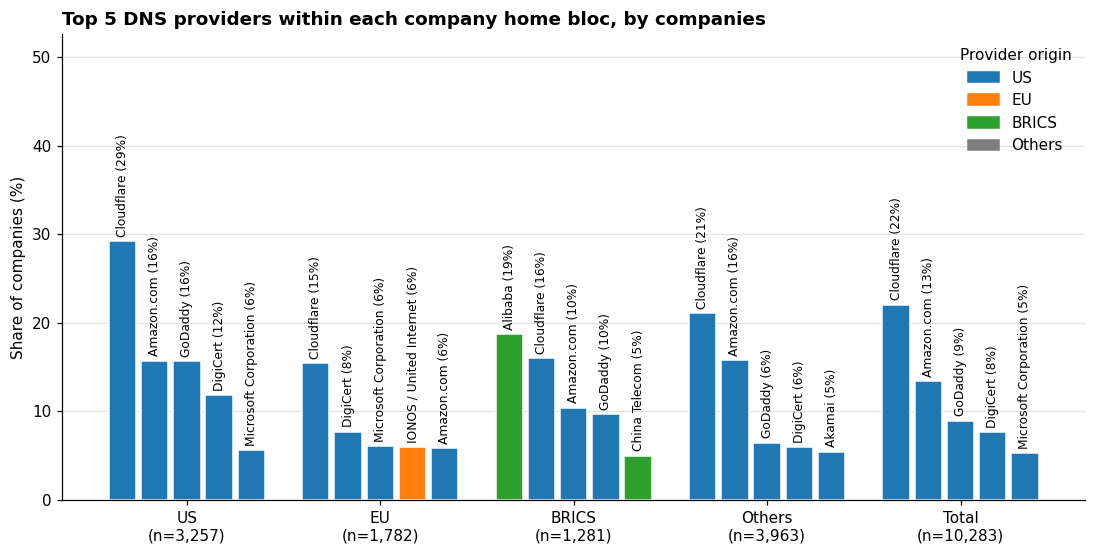

,bloco_empresa,provedor,bloco_provedor,participacao_receita
2176,US,Akamai,US,19.4
2241,US,DigiCert,US,15.4
2225,US,"Cloudflare, Inc.",US,12.3
2184,US,"Amazon.com, Inc.",US,9.3
2325,US,Microsoft Corporation,US,6.1
198,EU,Akamai,US,14.2
278,EU,DigiCert,US,11.4
252,EU,"Cloudflare, Inc.",US,10.2
204,EU,"Amazon.com, Inc.",US,6.0
406,EU,Microsoft Corporation,US,5.9


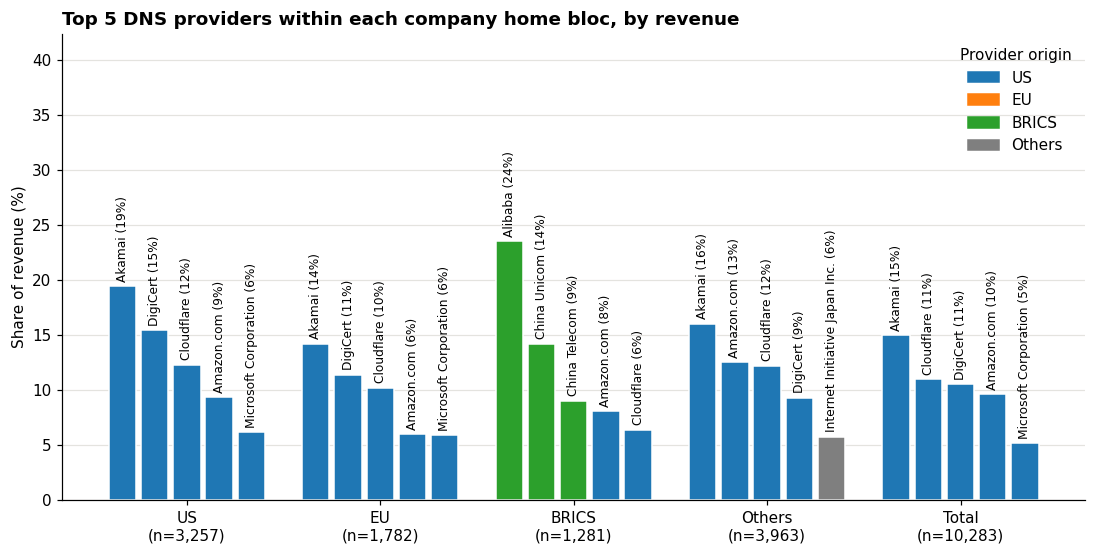

In [93]:
# GRÁFICO 1: os principais provedores de CADA bloco (eixo X = blocos), um gráfico por ponderação
# Cada bloco tem os seus próprios maiores provedores (ex.: Alibaba aparece só no BRICS),
# então aqui eu pego os TOP_N maiores dentro de cada bloco, e não os maiores do Total.
from matplotlib.patches import Patch

TOP_N = 5   # quantos provedores mostrar por bloco (com 1, fica só o principal de cada bloco)

# origem do provedor (bloco do país do provedor), que vai definir a cor da barra
origem_provedor = ep.drop_duplicates("provedor").set_index("provedor")["bloco_provedor"]

# legenda das cores: um quadradinho para cada bloco de origem do provedor
legenda = [Patch(color=CORES_BLOCOS[b], label=b) for b in ORDEM_BLOCOS[:-1]]

for pond, unidade in PONDERACOES.items():
    col = f"participacao_{pond}"

    # ordeno do maior para o menor e fico com as TOP_N primeiras linhas de cada bloco
    top_por_bloco = (por_provedor.sort_values(col, ascending=False)
                                 .groupby("bloco_empresa")
                                 .head(TOP_N)
                                 .copy())

    # coloco os blocos na ordem padrão (e, dentro de cada um, do maior para o menor)
    top_por_bloco["bloco_empresa"] = pd.Categorical(top_por_bloco["bloco_empresa"], categories=ORDEM_BLOCOS, ordered=True)
    top_por_bloco = top_por_bloco.sort_values(["bloco_empresa", col], ascending=[True, False])

    # nome curto do provedor para o rótulo ("Cloudflare, Inc." -> "Cloudflare") e origem
    top_por_bloco["nome_curto"] = top_por_bloco["provedor"].str.split(",").str[0]
    top_por_bloco["bloco_provedor"] = top_por_bloco["provedor"].map(origem_provedor)

    display(top_por_bloco[["bloco_empresa", "provedor", "bloco_provedor", col]].round(1))
    salvar_tabela(top_por_bloco[["bloco_empresa", "provedor", "bloco_provedor", col]], "conc_top_provedores_por_bloco", pond)

    fig, ax = plt.subplots(figsize=(12, 5.5))

    x = 0                    # posição da próxima barra no eixo X
    centros_dos_blocos = []  # posição do meio de cada bloco, onde vai o rótulo do eixo X

    for bloco in ORDEM_BLOCOS:
        dados = top_por_bloco[top_por_bloco["bloco_empresa"] == bloco]
        posicoes = range(x, x + len(dados))

        # a cor da barra mostra a ORIGEM do provedor (bloco do país do provedor)
        barras = ax.bar(posicoes, dados[col], width=0.85,
                        color=dados["bloco_provedor"].map(CORES_BLOCOS), edgecolor="white")

        # escrevo o nome do provedor e a participação em cima de cada barra (na vertical)
        ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados[col])],
                     rotation=90, padding=3, fontsize=8)

        centros_dos_blocos.append(x + (len(dados) - 1) / 2)
        x += len(dados) + 1  # deixo uma posição vazia entre um bloco e outro

    ax.set_xticks(centros_dos_blocos)
    ax.set_xticklabels(rotulos_com_n(n_empresas))
    ax.set_ylim(0, top_por_bloco[col].max() * 1.8)   # espaço para os nomes em cima das barras
    ax.set_title(f"Top {TOP_N} DNS providers within each company home bloc, by {unidade}")
    ax.set_ylabel(f"Share of {unidade} (%)")
    ax.legend(handles=legenda, title="Provider origin", loc="upper right")

    salvar_figura(fig, "fig_conc_top_provedores", pond)
    plt.show()

## 4. HHI e nº efetivo de provedores por bloco

Para o HHI, as participações de cada bloco precisam somar 100%. Nos métodos `fracionado` e
`principal` isso já acontece. No método `uso` eu recalculo a participação dividindo pelo total
de `valor` do bloco, ou seja, a fatia de cada provedor no total de **relações empresa–provedor**.

Para cada bloco calculo:
- `HHI` = soma de (participação em %)²
- `n_efetivo` = 10.000 ÷ HHI
- `top1`, `top5` e `top10`: fatia (%) do maior, dos 5 maiores e dos 10 maiores provedores

In [94]:
tab_hhi = {}
for pond, unidade in PONDERACOES.items():
    valor = f"valor_{pond}"

    # participação (%) que soma 100 dentro de cada bloco
    por_provedor[f"part_100_{pond}"] = 100 * por_provedor[valor] / por_provedor.groupby("bloco_empresa")[valor].transform("sum")

    # posição do provedor dentro do bloco (1 = maior)
    por_provedor[f"posicao_{pond}"] = por_provedor.groupby("bloco_empresa")[f"part_100_{pond}"].rank(ascending=False, method="first")

    # o HHI é a soma dos quadrados das participações
    part_ao_quadrado = por_provedor[f"part_100_{pond}"] ** 2

    tab = pd.DataFrame({
        "n_companies": n_empresas,
        "n_providers": por_provedor.groupby("bloco_empresa")["provedor"].nunique(),
        "HHI": part_ao_quadrado.groupby(por_provedor["bloco_empresa"]).sum(),
    }).reindex(ORDEM_BLOCOS)

    tab["n_efetivo"] = 10_000 / tab["HHI"]

    # fatia do maior, dos 5 maiores e dos 10 maiores provedores
    for k in [1, 5, 10]:
        maiores = por_provedor[por_provedor[f"posicao_{pond}"] <= k]
        tab[f"top{k}"] = maiores.groupby("bloco_empresa")[f"part_100_{pond}"].sum()

    tab_hhi[pond] = tab
    print(f"By {unidade}")
    display(tab.round(1))
    salvar_tabela(tab, "conc_hhi_blocos", pond)

By companies


,n_companies,n_providers,HHI,n_efetivo,top1,top5,top10
bloco_empresa,,,,,,,
US,3257,264,1552.2,6.4,29.2,78.0,88.6
EU,1782,400,491.5,20.3,15.4,41.0,58.7
BRICS,1281,181,903.5,11.1,18.7,59.8,75.9
Others,3963,472,865.3,11.6,21.1,54.7,68.7
Total,10283,1112,878.6,11.4,22.1,57.3,69.1


By revenue


,n_companies,n_providers,HHI,n_efetivo,top1,top5,top10
bloco_empresa,,,,,,,
US,3257,264,951.0,10.5,19.4,62.6,77.0
EU,1782,400,579.9,17.2,14.2,47.6,62.2
BRICS,1281,181,1032.0,9.7,23.5,61.1,80.3
Others,3963,472,731.4,13.7,16.0,55.7,67.0
Total,10283,1112,626.1,16.0,15.0,51.1,64.6


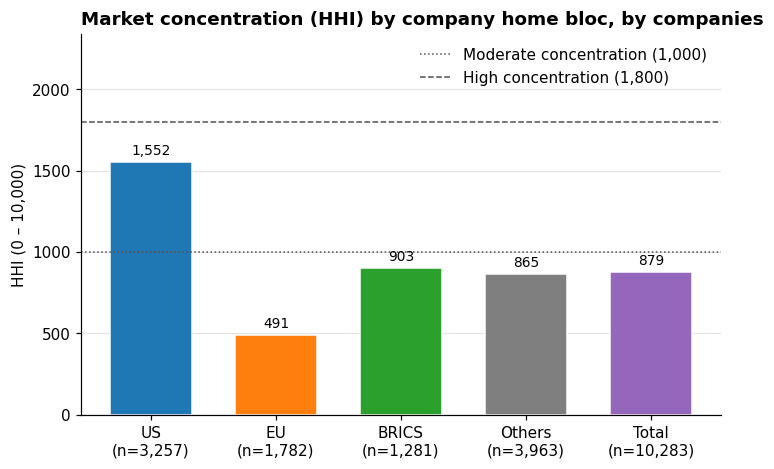

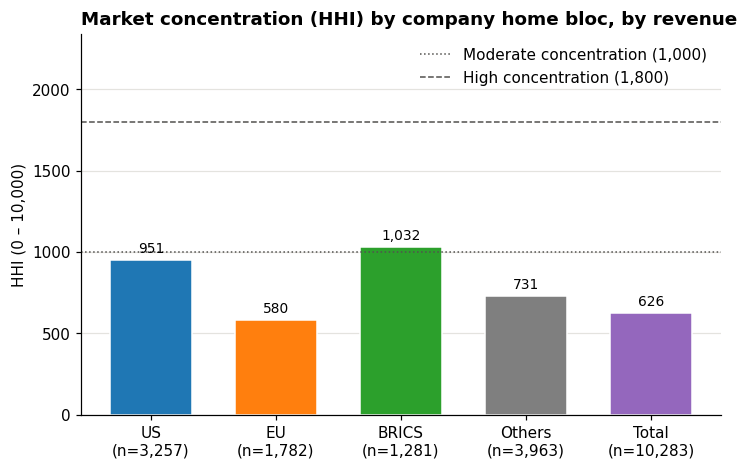

In [95]:
# GRÁFICO 2: HHI por bloco, com as linhas de referência de 1.000 e 1.800 (um gráfico por ponderação)
# mesma escala nos dois gráficos, para dar para comparar
y_max = max(max(t["HHI"].max() for t in tab_hhi.values()), 1800) * 1.3

for pond, unidade in PONDERACOES.items():
    tab = tab_hhi[pond]

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    barras = ax.bar(rotulos_com_n(n_empresas), tab["HHI"],
                    color=[CORES_BLOCOS[b] for b in tab.index], edgecolor="white", width=0.65)

    # escrevo em cima de cada barra o HHI
    ax.bar_label(barras, labels=[f"{h:,.0f}" for h in tab["HHI"]], padding=3, fontsize=9)

    # linhas de referência (aparecem na legenda)
    ax.axhline(1000, color="#52514e", linestyle=":", linewidth=1, label="Moderate concentration (1,000)")
    ax.axhline(1800, color="#52514e", linestyle="--", linewidth=1, label="High concentration (1,800)")
    ax.legend(loc="upper right")

    ax.set_ylim(0, y_max)
    ax.set_title(f"Market concentration (HHI) by company home bloc, by {unidade}")
    ax.set_ylabel("HHI (0 – 10,000)")

    salvar_figura(fig, "fig_conc_hhi_blocos", pond)
    plt.show()

## 5. Quanto do mercado fica com os maiores provedores?

Divido os provedores de cada bloco em faixas pela posição (1º, 2º ao 5º, 6º ao 10º e o resto)
e somo a participação de cada faixa. Cada barra soma 100%.

In [96]:
# classifico cada provedor em uma faixa, conforme a sua posição dentro do bloco
FAIXAS = ["Largest provider", "2nd to 5th", "6th to 10th", "All others"]

tab_faixas = {}
for pond, unidade in PONDERACOES.items():
    por_provedor[f"faixa_{pond}"] = pd.cut(por_provedor[f"posicao_{pond}"],
                                           bins=[0, 1, 5, 10, float("inf")], labels=FAIXAS)

    tab_faixas[pond] = (por_provedor.pivot_table(index="bloco_empresa", columns=f"faixa_{pond}",
                                                 values=f"part_100_{pond}", aggfunc="sum", observed=False)
                                    .reindex(ORDEM_BLOCOS))

    print(f"By {unidade}")
    display(tab_faixas[pond].round(1))
    salvar_tabela(tab_faixas[pond], "conc_faixas_blocos", pond)

By companies


faixa_empresas,Largest provider,2nd to 5th,6th to 10th,All others
bloco_empresa,,,,
US,29.2,48.8,10.6,11.4
EU,15.4,25.5,17.7,41.3
BRICS,18.7,41.1,16.1,24.1
Others,21.1,33.6,13.9,31.3
Total,22.1,35.2,11.8,30.9


By revenue


faixa_receita,Largest provider,2nd to 5th,6th to 10th,All others
bloco_empresa,,,,
US,19.4,43.1,14.4,23.0
EU,14.2,33.4,14.6,37.8
BRICS,23.5,37.6,19.1,19.7
Others,16.0,39.7,11.3,33.0
Total,15.0,36.2,13.4,35.4


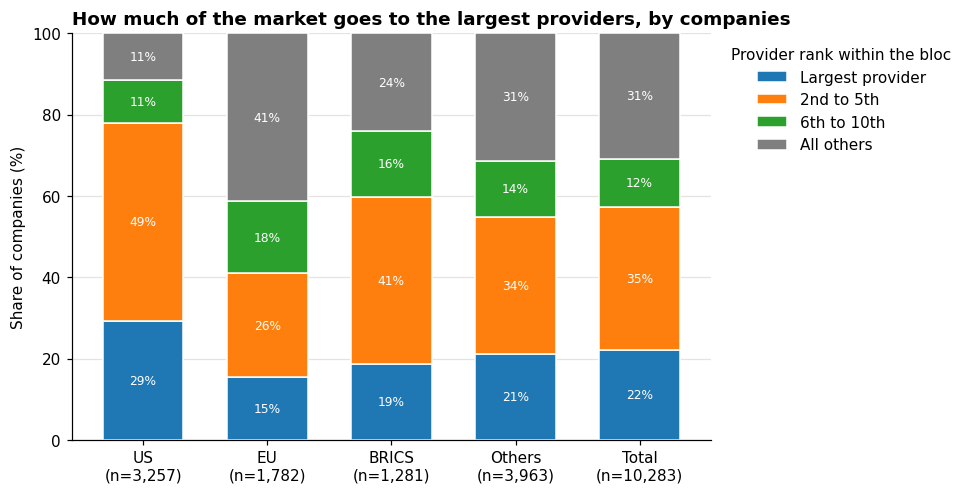

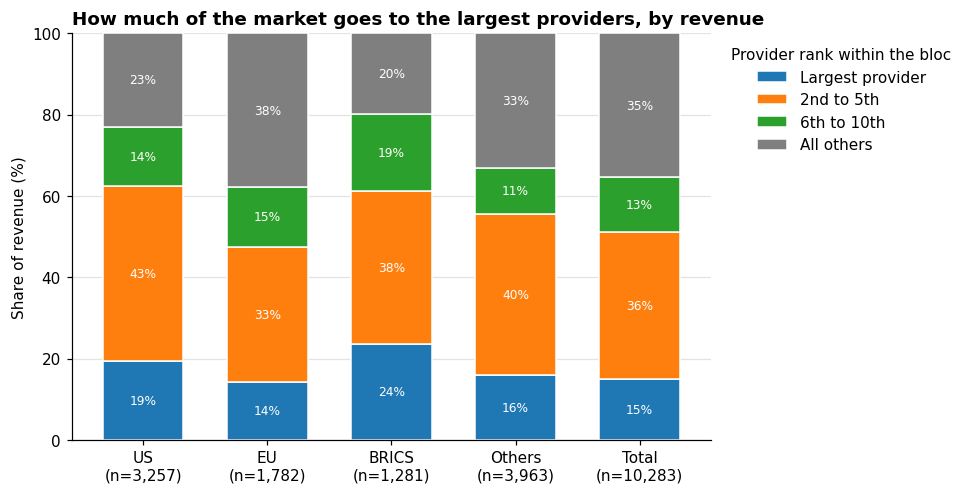

In [97]:
# GRÁFICO 3: barras empilhadas (cada barra = um bloco, soma 100%), um gráfico por ponderação
cores_faixas = [PALETA[0], PALETA[1], PALETA[2], PALETA[7]]

for pond, unidade in PONDERACOES.items():
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    tab_faixas[pond].plot.bar(ax=ax, stacked=True, width=0.65, color=cores_faixas, edgecolor="white")

    # escrevo o % dentro de cada pedaço (só nos pedaços com 4% ou mais, para não poluir)
    for pedacos in ax.containers:
        ax.bar_label(pedacos, labels=[f"{v:.0f}%" if v >= 4 else "" for v in pedacos.datavalues],
                     label_type="center", fontsize=8, color="white")

    ax.set_title(f"How much of the market goes to the largest providers, by {unidade}")
    ax.grid(axis="x", visible=False)   # o pandas liga a grade vertical; deixo só a horizontal
    ax.set_xlabel("")
    ax.set_ylabel(f"Share of {unidade} (%)")
    ax.set_xticklabels(rotulos_com_n(n_empresas), rotation=0)
    ax.set_ylim(0, 100)
    ax.legend(title="Provider rank within the bloc", bbox_to_anchor=(1.01, 1), loc="upper left")

    salvar_figura(fig, "fig_conc_faixas_blocos", pond)
    plt.show()

## 6. Notas para a leitura

- O **Total** mistura mercados diferentes (países, idiomas, regulação). Por isso a comparação
  entre blocos é a leitura principal.
- O país do provedor é o país do **grupo controlador** do ASN, e não onde ficam os servidores
  (provedores *anycast*, como Cloudflare e Akamai, têm servidores no mundo todo).
- Todo gráfico sai nas duas ponderações (empresas e receita). Para gerar as versões de outro
  método, basta mudar `METODO` na primeira célula de código e rodar tudo de novo. Os arquivos
  saem com o método e a ponderação no nome (ex.: `_fracionado_receita`).

## 7. Visão dos provedores: ocorrências nos dados

Nesta seção olho do ponto de vista dos **provedores** (grupo econômico dono dos AS, `dp_as_org`,
o mesmo "provedor" das seções anteriores), mas contando a **infraestrutura**: quantas vezes cada
provedor aparece hospedando os servidores de nomes das empresas de cada bloco.

Lembrando a relação: cada AS pertence a uma única organização (`as_org`), uma organização pode ter
vários AS, e o grupo econômico junta várias organizações (ex.: as duas organizações do Alibaba,
ou as subsidiárias da Leaseweb em cada país).

| Coluna | O que é | Exemplo |
|---|---|---|
| `server_example` | servidor de nomes (NS) mais comum daquele provedor no bloco | ns3.google.com |
| `organization` | grupo econômico dono dos AS (`dp_as_org`) | Google LLC |
| `asn` | número(s) dos AS do provedor que aparecem no bloco | 15169 |
| `as_country` | país do provedor (`dp_as_country_code`) | US |
| `occurrences` | nº de ocorrências do provedor nos dados do bloco (linhas empresa × NS × IP) | 30,812 |
| `centralization_pct` | % que essas ocorrências representam no total do bloco | 35% |
| `revenue_pct` | % da receita do bloco atribuída ao provedor, repartindo a receita de cada empresa na proporção das suas ocorrências | 15% |
| `n_companies` / `companies_pct` | nº e % de empresas do bloco com pelo menos um NS nesse provedor | |

> Esta seção conta **ocorrências** (linhas do dataset), e não empresas, por isso **não depende**
> de `METODO`: uma empresa com 8 NS conta 8 vezes, uma com 2 conta 2. A versão por receita
> reparte a receita de cada empresa entre os provedores na mesma proporção das ocorrências.
> Os gráficos saem nas duas versões: por ocorrências e por receita.

In [98]:
# mesma ideia da seção 2: duplico as linhas trocando o bloco por "Total"
df_total = pd.concat([df, df.assign(bloco_empresa="Total")], ignore_index=True)

# receita de cada ocorrência: a receita da empresa dividida pelo nº de linhas dela
# (assim a receita de cada empresa é repartida entre os provedores na proporção das ocorrências)
df_total["receita_ocorrencia"] = df_total["revenue_ttm"] / df_total.groupby(["bloco_empresa", "rank"])["ns"].transform("size")


def mais_comum(serie):
    """Devolve o valor que mais aparece na série."""
    return serie.value_counts().index[0]


def lista_asn(serie):
    """Junta os ASNs diferentes em um texto, ex.: '16509, 14618'."""
    return ", ".join(str(a) for a in sorted(serie.unique()))


# uma linha por (bloco da empresa, provedor = grupo econômico dono dos AS)
tab_org = (df_total.groupby(["bloco_empresa", "provedor"], as_index=False)
                   .agg(server_example=("ns", mais_comum),               # NS mais frequente
                        asn=("asn", lista_asn),                          # AS do provedor no bloco
                        as_country=("pais_provedor", mais_comum),
                        occurrences=("ns", "size"),                      # nº de linhas (empresa x NS x IP)
                        revenue=("receita_ocorrencia", "sum"),           # receita repartida pelas ocorrências
                        n_companies=("rank", "nunique"))
                   .rename(columns={"provedor": "organization"}))

# centralização = ocorrências do provedor / total de ocorrências do bloco
tab_org["centralization_pct"] = 100 * tab_org["occurrences"] / tab_org.groupby("bloco_empresa")["occurrences"].transform("sum")

# mesma ideia, com a receita repartida pelas ocorrências
tab_org["revenue_pct"] = 100 * tab_org["revenue"] / tab_org.groupby("bloco_empresa")["revenue"].transform("sum")

# % das empresas do bloco que têm pelo menos um NS nesse provedor
tab_org["companies_pct"] = 100 * tab_org["n_companies"] / tab_org["bloco_empresa"].map(n_empresas)

# blocos na ordem padrão e, dentro de cada um, do provedor com mais ocorrências para o com menos
tab_org["bloco_empresa"] = pd.Categorical(tab_org["bloco_empresa"], categories=ORDEM_BLOCOS, ordered=True)
tab_org = tab_org.sort_values(["bloco_empresa", "occurrences"], ascending=[True, False])
tab_org["position"] = tab_org.groupby("bloco_empresa", observed=True).cumcount() + 1   # 1 = maior do bloco

COLUNAS_ORG = ["bloco_empresa", "position", "server_example", "organization", "asn", "as_country",
               "occurrences", "centralization_pct", "revenue_pct", "n_companies", "companies_pct"]
tab_org = tab_org[COLUNAS_ORG]

# as duas versões desta seção: coluna usada, sufixo do arquivo e texto do eixo
VERSOES_ORG = {
    "ocorrencias": ("centralization_pct", "Share of name server occurrences (%)"),
    "receita": ("revenue_pct", "Share of revenue, split by name server occurrences (%)"),
}

# como esta tabela não muda com METODO, salvo sem o método no nome
tab_org.to_csv(PASTA_TAB / "conc_org_ocorrencias.csv", index=False)
print(f"{tab_org['organization'].nunique():,} provedores diferentes nos dados")

1,112 provedores diferentes nos dados


In [99]:
# TABELA DE VISUALIZAÇÃO: os maiores provedores de cada bloco (no formato da tabela do artigo)
TOP_ORG = 3   # quantos provedores mostrar por bloco

top_org = tab_org[tab_org["position"] <= TOP_ORG]
display(top_org.style
               .format({"occurrences": "{:,}", "n_companies": "{:,}", "centralization_pct": "{:.1f}%",
                        "revenue_pct": "{:.1f}%", "companies_pct": "{:.1f}%"})
               .hide(axis="index"))

bloco_empresa,position,server_example,organization,asn,as_country,occurrences,centralization_pct,revenue_pct,n_companies,companies_pct
US,1,blue.foundationdns.org,"Cloudflare, Inc.",13335,US,"4,577",34.8%,12.3%,960,29.5%
US,2,ns1.siteground.net,"Amazon.com, Inc.","14618, 16509",US,"2,032",15.5%,9.3%,522,16.0%
US,3,ns2.dnsmadeeasy.com,DigiCert,"12008, 16552, 19905, 399153, 399154",US,"1,621",12.3%,15.4%,403,12.4%
EU,1,blue.foundationdns.net,"Cloudflare, Inc.",13335,US,"1,567",23.3%,10.5%,285,16.0%
EU,2,a28-65.akam.net,Akamai,"21342, 63949",US,490,7.3%,14.4%,84,4.7%
EU,3,ns1-02.azure-dns.com,Microsoft Corporation,"8069, 8075",US,427,6.3%,5.9%,121,6.8%
BRICS,1,vip4.alidns.com,Alibaba,"37963, 45102, 134963",CN,"2,984",34.1%,23.6%,249,19.4%
BRICS,2,john.ns.cloudflare.com,"Cloudflare, Inc.",13335,US,"1,472",16.8%,6.4%,207,16.2%
BRICS,3,ns3.dnsv5.com,Tencent,"45090, 132203",CN,645,7.4%,3.3%,94,7.3%
Others,1,roan.ns.cloudflare.com,"Cloudflare, Inc.",13335,US,"4,497",29.1%,12.7%,856,21.6%


In [100]:
# TABELA DE VISUALIZAÇÃO: os 10 maiores provedores do Total, comparados entre os blocos
# (uma tabela por versão: % das ocorrências do bloco e % da receita do bloco)
for versao, (col, texto) in VERSOES_ORG.items():
    maiores_total = tab_org[tab_org["bloco_empresa"] == "Total"].nlargest(10, col)["organization"]

    tab_org_blocos = (tab_org[tab_org["organization"].isin(maiores_total)]
                      .pivot_table(index="organization", columns="bloco_empresa",
                                   values=col, aggfunc="sum", observed=False)
                      .reindex(columns=ORDEM_BLOCOS)
                      .fillna(0)
                      .sort_values("Total", ascending=False))

    # o degradê de cor ajuda a achar os valores mais altos de cada coluna
    print(texto)
    display(tab_org_blocos.style.format("{:.1f}%").background_gradient(cmap="Blues", axis=0))
    tab_org_blocos.to_csv(PASTA_TAB / f"conc_org_top10_blocos_{versao}.csv")

Share of name server occurrences (%)


bloco_empresa,US,EU,BRICS,Others,Total
organization,,,,,
"Cloudflare, Inc.",34.8%,23.3%,16.8%,29.1%,27.5%
"Amazon.com, Inc.",15.5%,6.3%,6.7%,15.9%,12.5%
Alibaba,0.1%,0.0%,34.1%,1.7%,7.4%
Akamai,7.8%,7.3%,3.9%,8.3%,7.1%
DigiCert,12.3%,6.2%,1.1%,5.0%,6.6%
Microsoft Corporation,5.5%,6.3%,1.6%,5.5%,4.9%
GoDaddy,7.8%,1.0%,2.9%,3.3%,4.2%
Tencent,0.0%,0.0%,7.4%,0.3%,1.6%
NSONE Inc,2.8%,1.3%,0.1%,1.4%,1.5%


Share of revenue, split by name server occurrences (%)


bloco_empresa,US,EU,BRICS,Others,Total
organization,,,,,
Akamai,19.4%,14.4%,3.2%,16.0%,15.0%
"Cloudflare, Inc.",12.3%,10.5%,6.4%,12.7%,11.2%
DigiCert,15.4%,11.4%,0.5%,9.3%,10.5%
"Amazon.com, Inc.",9.3%,6.0%,7.7%,12.2%,9.4%
Microsoft Corporation,6.1%,5.9%,2.5%,4.9%,5.1%
Alibaba,0.0%,0.0%,23.6%,0.4%,3.9%
NSONE Inc,5.1%,5.5%,0.0%,1.2%,3.1%
China Unicom,0.0%,0.0%,13.4%,0.5%,2.3%
GoDaddy,2.5%,0.4%,4.1%,1.6%,2.1%


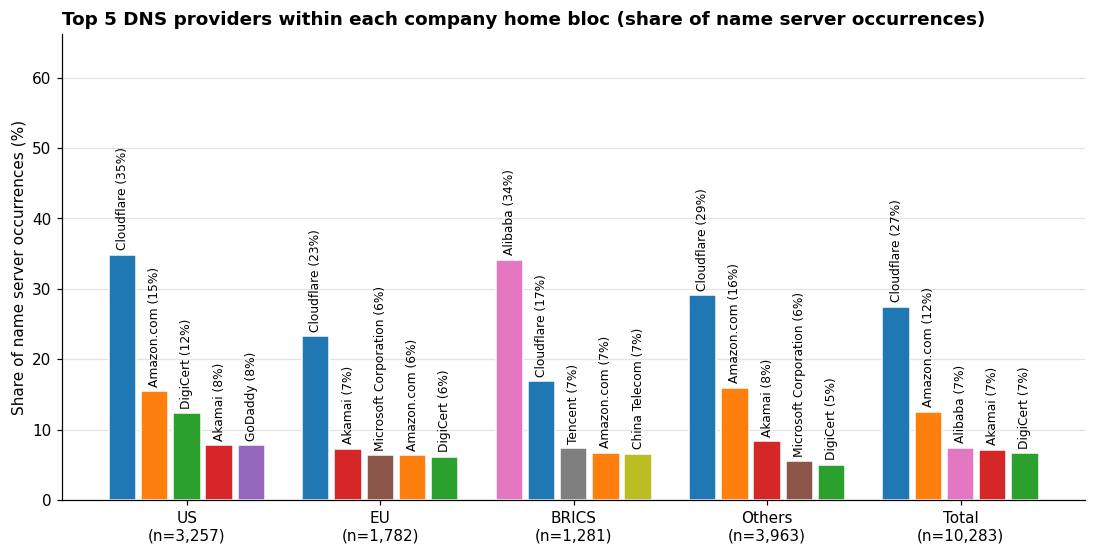

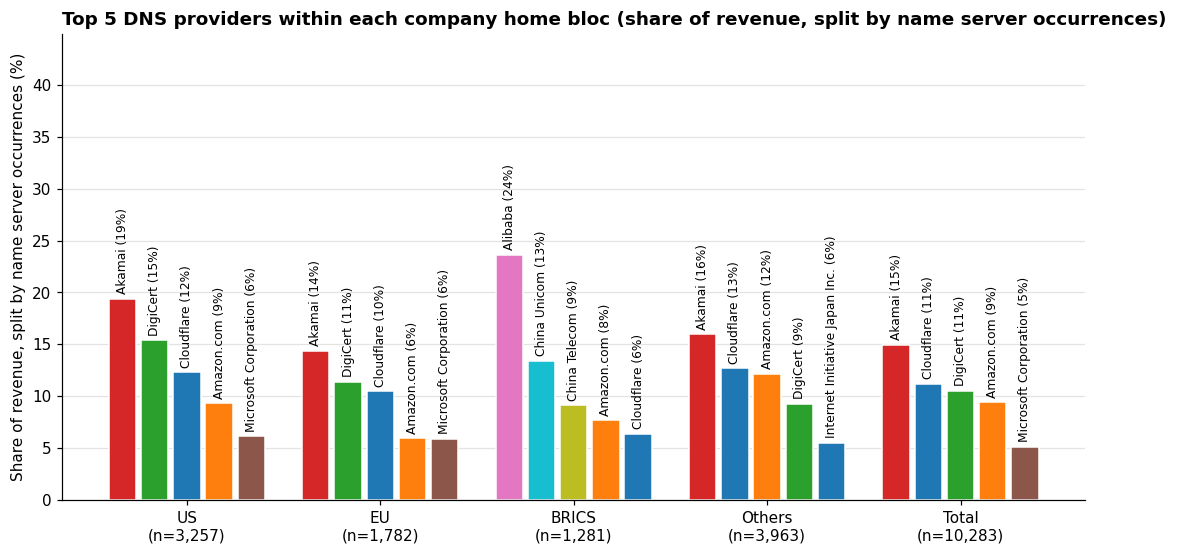

In [101]:
# GRÁFICO 4: os maiores provedores de cada bloco (mesmo formato do gráfico 1), um gráfico por versão
TOP_ORG_GRAFICO = 5


def top_por_grupo(tabela, grupo, col, n):
    """As n linhas com maior `col` dentro de cada grupo, do maior para o menor."""
    return tabela.sort_values([grupo, col], ascending=[True, False]).groupby(grupo, observed=True).head(n).copy()


# uma cor para cada provedor, que se repete em todos os blocos e nas duas versões
orgs_no_grafico = pd.unique(pd.concat([top_por_grupo(tab_org, "bloco_empresa", col, TOP_ORG_GRAFICO)["organization"]
                                       for col, _ in VERSOES_ORG.values()]))
COR_ORG = {org: PALETA[i % len(PALETA)] for i, org in enumerate(orgs_no_grafico)}

for versao, (col, texto) in VERSOES_ORG.items():
    dados_grafico = top_por_grupo(tab_org, "bloco_empresa", col, TOP_ORG_GRAFICO)

    # nome curto para o rótulo (o que vem antes da vírgula: "Cloudflare, Inc." -> "Cloudflare")
    dados_grafico["nome_curto"] = dados_grafico["organization"].str.split(",").str[0]

    fig, ax = plt.subplots(figsize=(12, 5.5))

    x = 0                    # posição da próxima barra no eixo X
    centros_dos_blocos = []  # posição do meio de cada bloco, onde vai o rótulo do eixo X

    for bloco in ORDEM_BLOCOS:
        dados = dados_grafico[dados_grafico["bloco_empresa"] == bloco]
        posicoes = range(x, x + len(dados))

        barras = ax.bar(posicoes, dados[col], width=0.85,
                        color=dados["organization"].map(COR_ORG), edgecolor="white")

        # rótulo: "Cloudflare (35%)"
        ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados[col])],
                     rotation=90, padding=3, fontsize=8)

        centros_dos_blocos.append(x + (len(dados) - 1) / 2)
        x += len(dados) + 1  # deixo uma posição vazia entre um bloco e outro

    ax.set_xticks(centros_dos_blocos)
    ax.set_xticklabels(rotulos_com_n(n_empresas))
    ax.set_ylim(0, dados_grafico[col].max() * 1.9)   # espaço para os rótulos
    ax.set_title(f"Top {TOP_ORG_GRAFICO} DNS providers within each company home bloc ({texto[:-4].lower()})")
    ax.set_ylabel(texto)

    # figura sem o método no nome, pelo mesmo motivo da tabela
    fig.savefig(PASTA_FIG / f"fig_conc_top_org_{versao}.png", dpi=200, bbox_inches="tight")
    plt.show()

### 7.1 Os 5 países com maior receita

Mesma visão de ocorrências, mas olhando país por país. Escolho os 5 países cujas empresas, somadas,
têm a maior receita (`revenue_ttm`) e mostro os 5 maiores provedores (`dp_as_org`) de cada um.

In [102]:
TOP_PAISES = 5        # quantos países mostrar
TOP_PROV_PAIS = 5     # quantos provedores mostrar por país

# receita total de cada país (cada empresa contada uma vez só)
receita_pais = (df.drop_duplicates("rank")
                  .groupby("company_country")["revenue_ttm"].sum()
                  .sort_values(ascending=False))
maiores_paises = receita_pais.head(TOP_PAISES).index.tolist()
print("Países:", maiores_paises)

# só os países escolhidos; a receita de cada empresa é repartida pelas suas ocorrências
df_paises = df[df["company_country"].isin(maiores_paises)].copy()
df_paises["receita_ocorrencia"] = df_paises["revenue_ttm"] / df_paises.groupby("rank")["ns"].transform("size")

# uma linha por (país da empresa, provedor)
tab_paises = (df_paises.groupby(["company_country", "provedor"], as_index=False)
                       .agg(bloco_provedor=("bloco_provedor", "first"),   # origem do provedor
                            occurrences=("ns", "size"),
                            revenue=("receita_ocorrencia", "sum"),
                            n_companies=("rank", "nunique")))

# centralização = ocorrências do provedor / total de ocorrências do país (e o mesmo para a receita)
tab_paises["centralization_pct"] = 100 * tab_paises["occurrences"] / tab_paises.groupby("company_country")["occurrences"].transform("sum")
tab_paises["revenue_pct"] = 100 * tab_paises["revenue"] / tab_paises.groupby("company_country")["revenue"].transform("sum")

# % das empresas do país que têm pelo menos um NS nesse provedor
empresas_pais = df_paises.groupby("company_country")["rank"].nunique()
tab_paises["companies_pct"] = 100 * tab_paises["n_companies"] / tab_paises["company_country"].map(empresas_pais)

# países do mais rico para o menos rico e, dentro de cada um, do maior provedor para o menor
tab_paises["company_country"] = pd.Categorical(tab_paises["company_country"], categories=maiores_paises, ordered=True)
tab_paises = tab_paises.sort_values(["company_country", "occurrences"], ascending=[True, False])
tab_paises["position"] = tab_paises.groupby("company_country", observed=True).cumcount() + 1

top_paises = tab_paises[tab_paises["position"] <= TOP_PROV_PAIS]
display(top_paises.style
                  .format({"occurrences": "{:,}", "n_companies": "{:,}", "revenue": "{:,.0f}",
                           "centralization_pct": "{:.1f}%", "revenue_pct": "{:.1f}%", "companies_pct": "{:.1f}%"})
                  .hide(axis="index"))
top_paises.to_csv(PASTA_TAB / "conc_org_top_paises_receita.csv", index=False)

Países: ['United States', 'China', 'Japan', 'Germany', 'United Kingdom']


company_country,provedor,bloco_provedor,occurrences,revenue,n_companies,centralization_pct,revenue_pct,companies_pct,position
United States,"Cloudflare, Inc.",US,"4,577","3,047,736,017,148",960,34.8%,12.3%,29.5%,1
United States,"Amazon.com, Inc.",US,"2,032","2,313,217,625,945",522,15.5%,9.3%,16.0%,2
United States,DigiCert,US,"1,621","3,812,596,804,891",403,12.3%,15.4%,12.4%,3
United States,Akamai,US,"1,022","4,798,595,560,272",173,7.8%,19.4%,5.3%,4
United States,GoDaddy,US,"1,022","621,245,661,148",511,7.8%,2.5%,15.7%,5
China,Alibaba,BRICS,"2,960","2,491,000,610,616",247,56.5%,33.7%,51.1%,1
China,Tencent,BRICS,645,"349,892,803,178",94,12.3%,4.7%,19.5%,2
China,China Telecom,BRICS,573,"961,664,087,343",158,10.9%,13.0%,32.7%,3
China,China Unicom,BRICS,380,"1,412,827,207,722",166,7.2%,19.1%,34.4%,4
China,China Mobile,BRICS,261,"445,341,369,025",116,5.0%,6.0%,24.0%,5


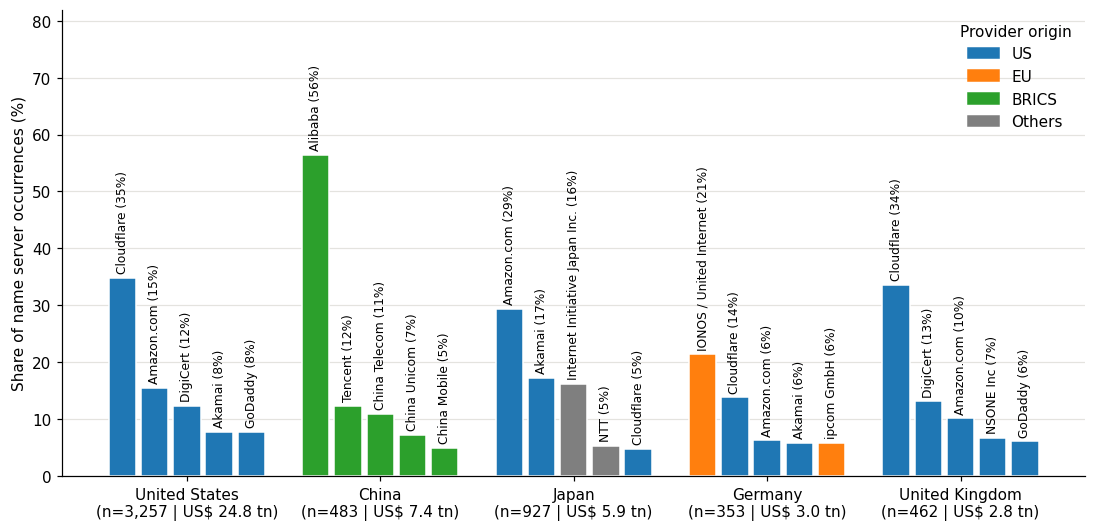

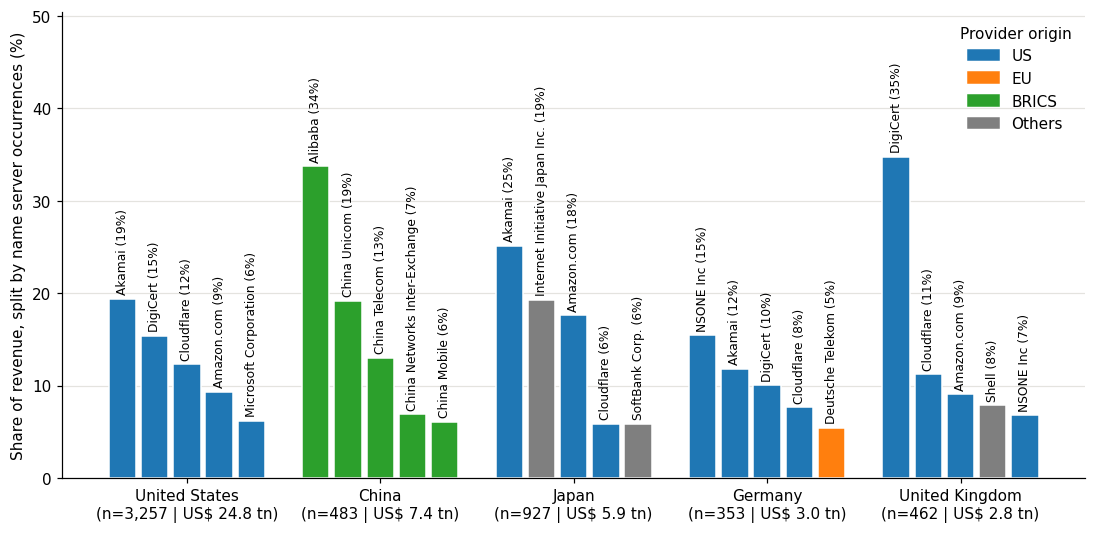

: 

In [ ]:
# GRÁFICO 5: os maiores provedores dos países com maior receita (mesmo formato do gráfico 4),
# um gráfico por versão; a cor da barra mostra a ORIGEM do provedor (bloco do país do provedor)
legenda = [Patch(color=CORES_BLOCOS[b], label=b) for b in ORDEM_BLOCOS[:-1]]

for versao, (col, texto) in VERSOES_ORG.items():
    dados_grafico = top_por_grupo(tab_paises, "company_country", col, TOP_PROV_PAIS)
    dados_grafico["nome_curto"] = dados_grafico["provedor"].str.split(",").str[0]

    fig, ax = plt.subplots(figsize=(12, 5.5))

    x = 0                     # posição da próxima barra no eixo X
    centros_dos_paises = []   # posição do meio de cada país, onde vai o rótulo do eixo X

    for pais in maiores_paises:
        dados = dados_grafico[dados_grafico["company_country"] == pais]
        posicoes = range(x, x + len(dados))

        barras = ax.bar(posicoes, dados[col], width=0.85,
                        color=dados["bloco_provedor"].map(CORES_BLOCOS), edgecolor="white")

        # rótulo: "Cloudflare (35%)"
        ax.bar_label(barras, labels=[f"{n} ({p:.0f}%)" for n, p in zip(dados["nome_curto"], dados[col])],
                     rotation=90, padding=3, fontsize=8)

        centros_dos_paises.append(x + (len(dados) - 1) / 2)
        x += len(dados) + 1  # deixo uma posição vazia entre um país e outro

    # rótulo do eixo X: país, nº de empresas e receita total (em trilhões de dólares)
    ax.set_xticks(centros_dos_paises)
    ax.set_xticklabels([f"{p}\n(n={empresas_pais[p]:,} | US$ {receita_pais[p] / 1e12:.1f} tn)" for p in maiores_paises])
    ax.set_ylim(0, dados_grafico[col].max() * 1.45)   # espaço para os rótulos
    ax.set_ylabel(texto)
    ax.legend(handles=legenda, title="Provider origin", loc="upper right")

    fig.savefig(PASTA_FIG / f"fig_conc_top_paises_receita_{versao}.png", dpi=200, bbox_inches="tight")
    plt.show()